In [2]:
import pandas as pd

archivos = ["BD 2024.xlsx", "BD 2025.xlsx", "BD 2026 ene-jul.xlsx"]

for a in archivos:
    hojas = pd.read_excel(a, sheet_name=None)
    for nombre, df in hojas.items():
        print(a, nombre, df.shape)

BD 2024.xlsx CE (8784, 16)
BD 2024.xlsx NE (8784, 16)
BD 2024.xlsx NE2 (8782, 16)
BD 2024.xlsx NE3 (8782, 16)
BD 2024.xlsx NO (8783, 16)
BD 2024.xlsx NO2 (8782, 16)
BD 2024.xlsx NO3 (8784, 16)
BD 2024.xlsx NTE (8782, 16)
BD 2024.xlsx NTE2 (8782, 16)
BD 2024.xlsx SE (8784, 16)
BD 2024.xlsx SE2 (8782, 16)
BD 2024.xlsx SE3 (8782, 16)
BD 2024.xlsx SO (8784, 16)
BD 2024.xlsx SO2 (8782, 16)
BD 2024.xlsx SUR (8782, 16)
BD 2025.xlsx CE (8759, 16)
BD 2025.xlsx NE (8758, 16)
BD 2025.xlsx NE2 (8758, 16)
BD 2025.xlsx NE3 (8759, 16)
BD 2025.xlsx NO (8759, 16)
BD 2025.xlsx NO2 (8758, 16)
BD 2025.xlsx NO3 (8759, 16)
BD 2025.xlsx NTE (8759, 16)
BD 2025.xlsx NTE2 (8758, 16)
BD 2025.xlsx SE (8759, 16)
BD 2025.xlsx SE2 (8759, 16)
BD 2025.xlsx SE3 (8758, 16)
BD 2025.xlsx SO (8758, 16)
BD 2025.xlsx SO2 (8758, 16)
BD 2025.xlsx SUR (8759, 16)
BD 2026 ene-jul.xlsx CE (5087, 16)
BD 2026 ene-jul.xlsx NE (5087, 16)
BD 2026 ene-jul.xlsx NE2 (5087, 16)
BD 2026 ene-jul.xlsx NE3 (5087, 16)
BD 2026 ene-jul.xlsx NO (5

In [3]:
import pandas as pd

archivos = ["BD 2024.xlsx", "BD 2025.xlsx", "BD 2026 ene-jul.xlsx"]

partes = []
for a in archivos:
    hojas = pd.read_excel(a, sheet_name=None)
    for estacion, d in hojas.items():
        d["estacion"] = estacion
        partes.append(d)

# Revisa que todas las hojas tengan las mismas columnas
columnas = {tuple(p.columns) for p in partes}
print(len(columnas), "estructura(s) distinta(s)")

df = pd.concat(partes, ignore_index=True)
print(df.shape)
df.to_csv("base_unida.csv", index=False)

2 estructura(s) distinta(s)
(339424, 18)


In [4]:
from collections import Counter

conteo = Counter(tuple(p.columns) for p in partes)
estructuras = list(conteo.keys())

for i, cols in enumerate(estructuras):
    print(f"Estructura {i+1}: {conteo[cols]} hojas")

print("Solo en la 1:", set(estructuras[0]) - set(estructuras[1]))
print("Solo en la 2:", set(estructuras[1]) - set(estructuras[0]))

Estructura 1: 15 hojas
Estructura 2: 30 hojas
Solo en la 1: {'Fecha y hora'}
Solo en la 2: {'date'}


In [5]:
for p in partes:
    p.rename(columns={"Fecha y hora": "date"}, inplace=True)

df = pd.concat(partes, ignore_index=True)
df["date"] = pd.to_datetime(df["date"])
print(df.shape)
df.to_csv("base_unida.csv", index=False)

(339424, 17)


In [6]:
faltantes = df.isna().mean().mul(100).round(1).sort_values(ascending=False)
print(faltantes)

PM2.5       27.9
RH          16.6
CO          12.0
NO          10.4
TOUT        10.1
SR           9.5
NO2          9.2
NOX          9.0
SO2          7.9
PRS          5.5
O3           5.0
RAINF        4.0
PM10         3.9
WDR          3.0
WSR          3.0
date         0.0
estacion     0.0
dtype: float64


In [7]:
print(df.groupby("estacion").apply(lambda g: g.isna().mean().mul(100).round(1)))

          date    CO    NO   NO2   NOX    O3  PM10  PM2.5   PRS  RAINF    RH  \
estacion                                                                       
CE         0.0  13.2   8.7   5.5   5.5   3.3   2.2   14.3   2.1    1.9   2.4   
NE         0.0   8.3   9.4   8.9   8.9   5.9   3.9    7.5   3.3    3.0   3.7   
NE2        0.0  18.3  27.2  23.4  23.7   5.8   4.4   54.0   4.1    3.1   3.7   
NE3        0.0  14.8  12.3  11.3  11.4   5.7   5.3   69.4   8.5    4.4   7.6   
NO         0.0  20.2  17.4  15.9  18.0   9.1   4.0   81.8   4.3    4.0  36.8   
NO2        0.0   5.3  14.7  13.4  13.4   3.4   2.4   18.7   1.7    1.5   2.1   
NO3        0.0  18.8  29.9  29.7  30.2  14.5  12.6   67.2  12.1   11.7  14.9   
NTE        0.0   3.5   4.2   2.6   1.9   3.7   2.9   10.6   1.7   13.9  89.5   
NTE2       0.0   3.9   1.2   1.1   1.1   4.2   2.1    9.0   1.2    1.2   1.6   
SE         0.0  19.0   4.1   2.4   2.4   2.5   3.2   18.5   3.9    2.4   2.4   
SE2        0.0  17.4   8.6  10.1   6.1  

/tmp/ipykernel_2396/3919612628.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  print(df.groupby("estacion").apply(lambda g: g.isna().mean().mul(100).round(1)))


In [8]:
df["mes"] = df["date"].dt.to_period("M")
tabla = df.groupby(["estacion", "mes"])["PM2.5"].apply(lambda x: x.isna().mean() * 100).unstack()
print(tabla.round(0))

mes       2024-01  2024-02  2024-03  2024-04  2024-05  2024-06  2024-07  \
estacion                                                                  
CE           16.0     34.0      5.0     37.0     61.0     27.0     13.0   
NE            3.0      8.0      6.0      7.0     11.0     49.0      2.0   
NE2           7.0      8.0      6.0     17.0     13.0     25.0     16.0   
NE3         100.0    100.0    100.0    100.0    100.0    100.0    100.0   
NO           21.0     30.0     59.0    100.0    100.0    100.0    100.0   
NO2          24.0     51.0     10.0      8.0     77.0     91.0     29.0   
NO3         100.0    100.0     86.0     48.0    100.0    100.0      9.0   
NTE          10.0      3.0      8.0      5.0      6.0      9.0     10.0   
NTE2          7.0      7.0      6.0     16.0     12.0     12.0      5.0   
SE           44.0     25.0     27.0     52.0     77.0     29.0     16.0   
SE2           5.0      2.0      3.0      3.0      4.0     16.0      7.0   
SE3           3.0      5.

In [9]:
validos = tabla <= 25
print(validos.sum(axis=1).sort_values())

estacion
NO       3
NO3      5
NE3     10
NE2     13
NO2     23
SE      23
SO      24
CE      25
SUR     25
SE3     27
SO2     27
NE      30
NTE     30
NTE2    31
SE2     31
dtype: int64


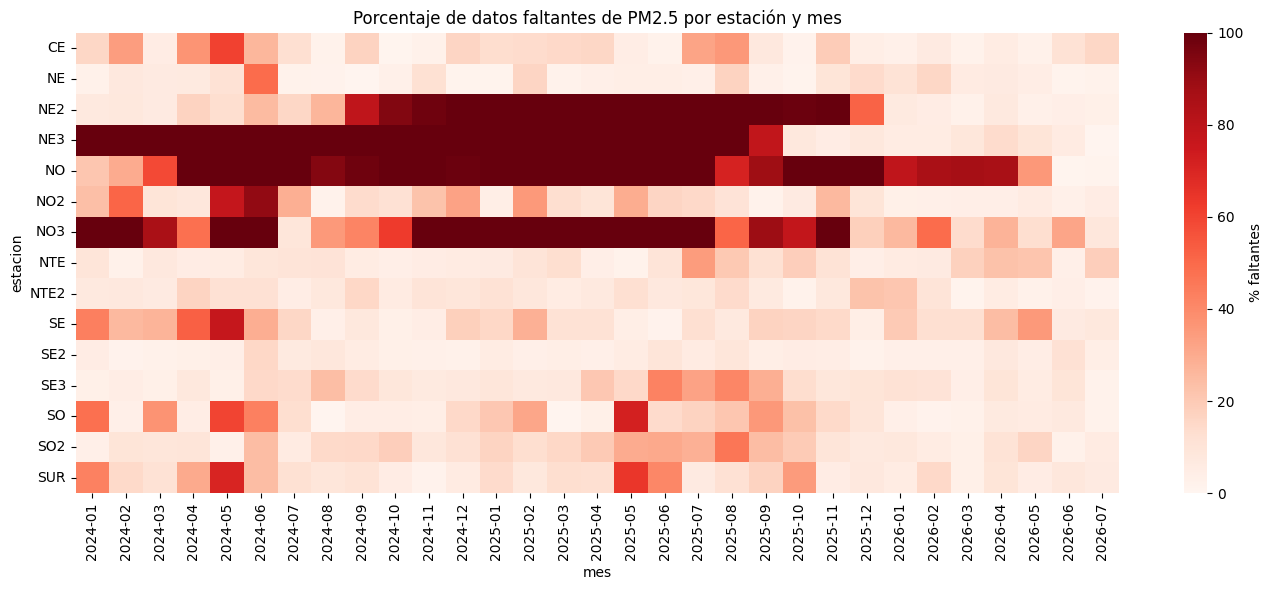

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
sns.heatmap(tabla, cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% faltantes"})
plt.title("Porcentaje de datos faltantes de PM2.5 por estación y mes")
plt.tight_layout()
plt.show()